# 07 — Credit portfolio risk

**Goal:** turn borrower-level PDs into portfolio-level losses for the 2015 book: loans the model
never saw in development or recalibration, whose real losses are known.

- **Expected loss** per loan = PD × LGD × EAD, with LGD and EAD *measured* from recoveries on
  earlier charge-offs;
- **loss distribution** from a one-factor Gaussian Monte Carlo model, giving VaR and Expected Shortfall;
- how the tail depends on **default correlation** and **portfolio size**.

All losses are **lifetime (36-month)** losses of principal, matching the PD; they are not one-year measures.

In [1]:
import os, sys, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pdmodel import config as C
pd.set_option("display.float_format", "{:.4f}".format)
PROC = ROOT / "data" / "processed"
from pdmodel import plots, portfolio as P, simulation as MC

In [2]:
S = pd.read_pickle(PROC / "samples.pkl")
cm = pd.read_pickle(PROC / "validation.pkl")["calibrated_model"]
oot = S["oot"]
hist = pd.concat([S["train"], S["test"], S["calib"]], ignore_index=True)   # charge-offs issued 2007-14

## 1. Loss given default and exposure at default

Measured on charged-off loans issued 2007–2014, by rating grade, so the 2015 book's own outcomes
never set its loss parameters.

- EAD ratio = principal still owed at charge-off ÷ funded amount
- LGD = 1 − (recoveries − collection fees) ÷ EAD

In [3]:
params = P.estimate_loss_parameters(hist, cm.grade(hist))
params

,defaults,ead_ratio,lgd,no_recovery
grade,,,,
1,1991,0.5352,0.8880,0.1577
2,3633,0.5425,0.8878,0.1448
3,4824,0.5555,0.8861,0.1455
4,5888,0.5623,0.8886,0.1423
5,7288,0.5697,0.8889,0.1493
6,8872,0.5901,0.8955,0.1496
7,11976,0.6132,0.8979,0.1505
all,44472,0.5768,0.8920,0.1483


In [4]:
P.loss_parameters_by_year(hist)

,defaults,ead_ratio,lgd,no_recovery
issue_year,,,,
2007,158,0.6331,0.9259,0.0063
2008,496,0.6564,0.9430,0.0302
2009,723,0.6575,0.9307,0.0138
2010,1000,0.6158,0.9258,0.0030
2011,1499,0.5801,0.9275,0.0120
2012,5903,0.5857,0.9089,0.0181
2013,12378,0.5736,0.8857,0.0763
2014,22315,0.5708,0.8856,0.2464


## 2. Expected loss, and what the 2015 book actually lost

In [5]:
port = P.build_portfolio(oot, cm.predict_pd(oot), cm.grade(oot), params)
pd.Series(P.summary(port)).map("{:,.4f}".format)

loans                         283,026.0000
exposure                3,624,300,800.0000
mean_pd                             0.1318
exposure_weighted_pd                0.1238
ead                     2,042,687,576.8913
el                        230,221,977.6046
el_rate                             0.0635
observed_dr                         0.1489
realised_loss             274,011,577.2408
realised_loss_rate                  0.0756
dtype: object

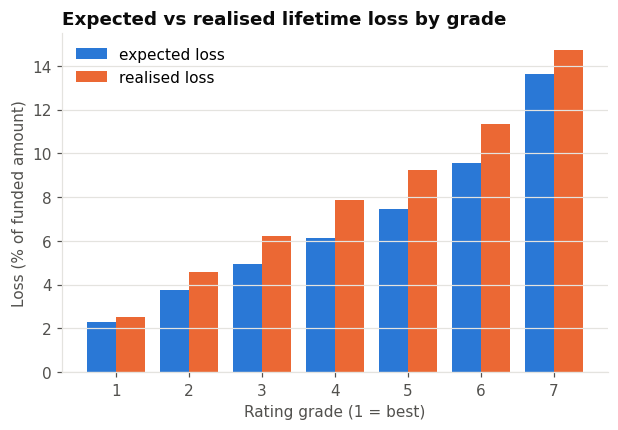

,loans,exposure,exposure_share,mean_pd,observed_dr,el,el_share,el_rate,realised_loss_rate
grade,,,,,,,,,
1,38722,603592975.0000,0.1665,0.0486,0.0508,13893052.2402,0.0603,0.0230,0.0252
2,41243,599101675.0000,0.1653,0.0779,0.0919,22437185.4455,0.0975,0.0375,0.0459
3,42034,563133400.0000,0.1554,0.1003,0.1190,27758281.0567,0.1206,0.0493,0.0622
4,41106,514148000.0000,0.1419,0.1225,0.1470,31439939.3199,0.1366,0.0611,0.0785
5,40987,487089800.0000,0.1344,0.1477,0.1703,36409983.5334,0.1582,0.0748,0.0923
6,40150,452642550.0000,0.1249,0.1809,0.2057,43224375.7774,0.1878,0.0955,0.1133
7,38784,404592400.0000,0.1116,0.2485,0.2601,55059160.2314,0.2392,0.1361,0.1475


In [6]:
seg = {c: P.el_by_segment(port, c) for c in ("grade", "purpose", "size_band")}
plots.el_by_grade(seg["grade"]); plt.show()
seg["grade"]

In [7]:
seg["purpose"].sort_values("exposure", ascending=False).head(8)

,loans,exposure,exposure_share,mean_pd,observed_dr,el,el_share,el_rate,realised_loss_rate
purpose,,,,,,,,,
debt_consolidation,160983,2136934625.0000,0.5896,0.1407,0.1573,147104193.6297,0.6390,0.0688,0.0803
credit_card,70650,978895750.0000,0.2701,0.1088,0.1223,50332175.2045,0.2186,0.0514,0.0577
home_improvement,17160,207252925.0000,0.0572,0.0977,0.1351,9543166.8609,0.0415,0.0460,0.0757
other,15227,127834625.0000,0.0353,0.1717,0.1686,10976180.8405,0.0477,0.0859,0.0931
major_purchase,5342,54703550.0000,0.0151,0.0904,0.1445,2288882.8566,0.0099,0.0418,0.0855
small_business,2425,32826400.0000,0.0091,0.2233,0.2297,3716637.6959,0.0161,0.1132,0.1443
medical,3146,23159450.0000,0.0064,0.1604,0.1783,1874618.3164,0.0081,0.0809,0.1031
car,2768,23150325.0000,0.0064,0.0973,0.1329,1109009.3177,0.0048,0.0479,0.0786


In [8]:
seg["size_band"]

,loans,exposure,exposure_share,mean_pd,observed_dr,el,el_share,el_rate,realised_loss_rate
size_band,,,,,,,,,
≤ $5k,45615,170019675.0000,0.0469,0.1424,0.1526,12425863.2709,0.0540,0.0731,0.0802
$5k–10k,97358,780980500.0000,0.2155,0.1402,0.1573,56637671.9151,0.2460,0.0725,0.0815
$10k–15k,57122,743987375.0000,0.2053,0.1335,0.1459,51090427.0258,0.2219,0.0687,0.0749
$15k–25k,59337,1191221400.0000,0.3287,0.1200,0.1397,72130323.7548,0.3133,0.0606,0.0718
> $25k,23594,738091850.0000,0.2037,0.1024,0.1372,37937691.6380,0.1648,0.0514,0.0751


Where does the gap between expected and realised loss come from: too few predicted defaults,
or too little loss per default?

In [9]:
d = port[port["default"] == 1]
pd.Series({"actual / predicted defaults": port["default"].sum() / port["pd"].sum(),
           "realised / expected loss per default": d["realised_loss"].sum() / (d["lgd"] * d["ead"]).sum()})

actual / predicted defaults            1.1294
realised / expected loss per default   1.0199
dtype: float64

## 3. Sensitivity of expected loss to PD and LGD

Expected loss as a share of funded amount; PDs scaled (rows), LGDs shifted (columns).

In [10]:
P.el_sensitivity(port)

,LGD -10%,LGD -5%,LGD +0%,LGD +5%,LGD +10%
PD x0.8,0.0451,0.0480,0.0508,0.0537,0.0565
PD x0.9,0.0508,0.0540,0.0572,0.0604,0.0636
PD x1,0.0564,0.0600,0.0635,0.0671,0.0706
PD x1.1,0.0620,0.0660,0.0699,0.0738,0.0777
PD x1.25,0.0705,0.0750,0.0794,0.0839,0.0883
PD x1.5,0.0846,0.0899,0.0953,0.1006,0.1060


## 4. Concentration

In [11]:
P.format_concentration(P.concentration(port))

,value
Loans,"283,026"
Largest single exposure ($),"35,000"
Largest single exposure (share),0.001%
Top 1% of loans (share of exposure),2.7%
"Herfindahl index, loans",4.93e-06
Effective number of loans (1 / HHI),"202,717"
"Herfindahl index, purpose",0.426
Largest purpose (share),debt_consolidation (59.0%)
"Herfindahl index, grade",0.145
Largest grade (share),1 (16.7%)


## 5. Default correlation

Two candidates for ρ:

- **estimated** by matching the variance of quarterly vintage default rates to the one-factor model
  (after removing binomial noise, and after removing changes in borrower mix the model explains);
- the **Basel other-retail formula**, per loan, at each loan's annualised PD: 16% for the safest loans,
  falling to 3% as PD rises.

In [12]:
vint = pd.concat([S[k].assign(pd=cm.predict_pd(S[k])) for k in S], ignore_index=True)
q = vint.groupby(vint["issue_d"].dt.to_period("Q")).agg(
    n=("default", "size"), observed_dr=("default", "mean"), mean_pd=("pd", "mean"))
rho_est, rho_tab = MC.estimate_correlation(q)
pd.Series(rho_est)

vintages             28.0000
mean_dr               0.1392
binomial_noise_var    0.0000
raw_var               0.0007
rho_raw               0.0126
mix_adjusted_var      0.0002
rho_mix_adjusted      0.0044
dtype: float64

In [13]:
pdv, lgd, ead = port["pd"].to_numpy(), port["lgd"].to_numpy(), port["ead"].to_numpy()
rho = MC.basel_retail_correlation(MC.annualised_pd(pdv, C.TERM_YEARS))
print(f"Basel retail rho per loan: {rho.min():.3f}-{rho.max():.3f}, EAD-weighted mean {np.average(rho, weights=ead):.3f}")

Basel retail rho per loan: 0.030-0.136, EAD-weighted mean 0.065


Every vintage with enough loans was issued between 2009 and 2015, a recovery with no recession,
so the estimate only measures how much default rates varied in good times. The simulation uses
the Basel correlation; section 8 shows how much the choice matters.

## 6. Monte Carlo loss distribution

For each scenario: draw the economy factor Z and a borrower factor εᵢ for every loan;
loan i defaults if √ρᵢ·Z + √(1−ρᵢ)·εᵢ < Φ⁻¹(PDᵢ). 20,000 scenarios × 283,000 loans takes about 30 seconds.

In [14]:
losses, _, _ = MC.simulate_losses(pdv, lgd, ead, rho, C.MC_SIMULATIONS, seed=C.MC_SEED)
exp = port["exposure"].sum()
risk = MC.risk_measures(losses, C.VAR_LEVELS, C.ES_LEVELS)
realised = port["realised_loss"].sum()
pd.DataFrame({"amount ($m)": pd.Series(risk) / 1e6, "% of funded": pd.Series(risk) / exp * 100})

,amount ($m),% of funded
expected_loss,230.5426,6.3610
std,87.9405,2.4264
var_0.95,394.1080,10.8740
var_0.99,487.4195,13.4487
es_0.975,493.2108,13.6084
es_0.99,545.2375,15.0439


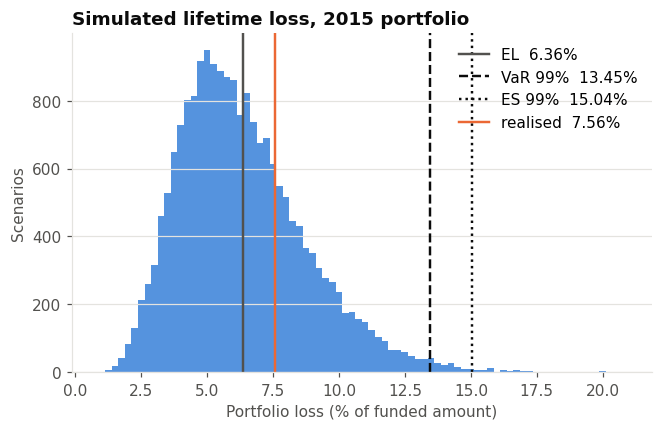

realised 2015 loss is at the 73% percentile of the simulation


In [15]:
plots.loss_distribution(losses / exp * 100, {k: v / exp * 100 for k, v in risk.items()}, realised / exp * 100)
plt.show()
print(f"realised 2015 loss is at the {(losses <= realised).mean():.0%} percentile of the simulation")

### Checks against the analytical results

Simulated expected loss should match PD × LGD × EAD, and with this many small loans the 99% VaR
should match the large-portfolio (Vasicek) formula.

In [16]:
el = MC.analytical_el(pdv, lgd, ead)
pd.DataFrame({"simulated": [risk["expected_loss"], risk["var_0.99"]],
              "analytical": [el, MC.asrf_quantile(pdv, lgd, ead, rho, 0.99)]},
             index=["expected loss", "VaR 99%"]).assign(difference=lambda t: t["simulated"] / t["analytical"] - 1)

,simulated,analytical,difference
expected loss,230542595.7728,230221977.6046,0.0014
VaR 99%,487419538.5600,487827115.9262,-0.0008


## 7. Convergence

Estimates from the first *n* scenarios, with bootstrap standard errors (% of funded amount).

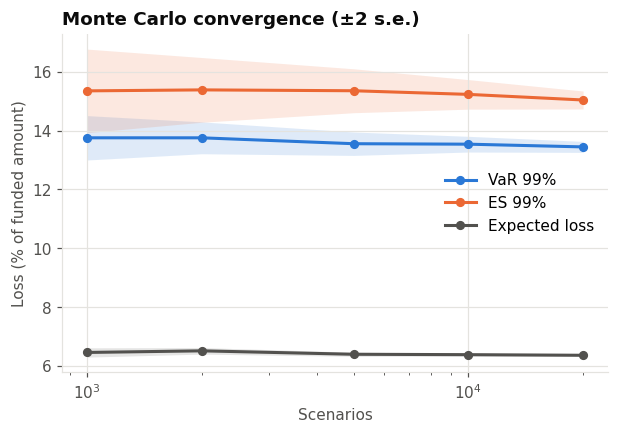

,expected_loss,el_se,var_0.99,var_0.99_se,es_0.99,es_0.99_se
scenarios,,,,,,
1000,6.4570,0.0789,13.7577,0.3775,15.3543,0.7104
2000,6.5122,0.0555,13.7573,0.2708,15.3877,0.5501
5000,6.3954,0.0350,13.5570,0.1992,15.3584,0.3736
10000,6.3816,0.0243,13.5410,0.1336,15.2348,0.2514
20000,6.3610,0.0172,13.4487,0.0936,15.0439,0.1528


In [17]:
conv = MC.convergence(losses, [1_000, 2_000, 5_000, 10_000, 20_000]) / exp * 100
plots.convergence_plot(conv); plt.show()
conv

## 8. Sensitivity to the default correlation

One ρ for every loan, 10,000 scenarios each (% of funded amount). Expected loss does not depend on ρ;
the tail does.

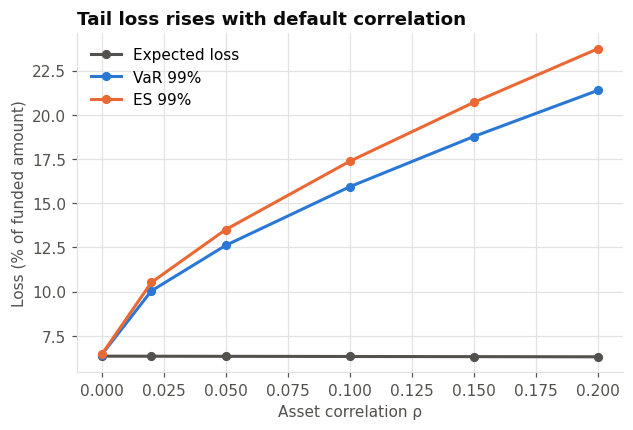

,expected_loss,std,var_0.95,var_0.99,es_0.975,es_0.99
rho,,,,,,
0.0000,6.3513,0.0360,6.4106,6.4331,6.4341,6.4451
0.0200,6.3471,1.3891,8.7940,10.0423,10.0031,10.5207
0.0500,6.3417,2.2108,10.3669,12.6190,12.5650,13.5119
0.1000,6.3325,3.1637,12.3141,15.9352,15.8461,17.3765
0.1500,6.3236,3.9235,13.9302,18.7771,18.6663,20.7053
0.2000,6.3152,4.5887,15.4066,21.3849,21.2517,23.7406


In [18]:
corr = {}
for r in C.CORRELATION_GRID:
    L, _, _ = MC.simulate_losses(pdv, lgd, ead, r, C.MC_SIMULATIONS // 2, seed=C.MC_SEED + 1)
    corr[r] = {k: v / exp * 100 for k, v in MC.risk_measures(L, C.VAR_LEVELS, C.ES_LEVELS).items()}
corr = pd.DataFrame(corr).T.rename_axis("rho")
plots.correlation_sensitivity(corr); plt.show()
corr

In [19]:
L_est, _, _ = MC.simulate_losses(pdv, lgd, ead, rho_est["rho_mix_adjusted"], C.MC_SIMULATIONS // 2, seed=C.MC_SEED + 3)
print(f"with the estimated rho ({rho_est['rho_mix_adjusted']:.3f}), the realised loss would be at the "
      f"{(L_est <= realised).mean():.1%} percentile")

with the estimated rho (0.004), the realised loss would be at the 95.8% percentile


## 9. Portfolio size

Random sub-portfolios of the 2015 book with the same correlation (% of funded amount).

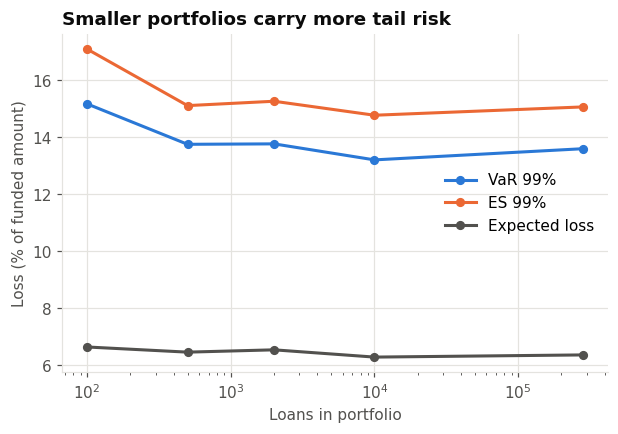

,expected_loss,std,var_0.95,var_0.99,es_0.975,es_0.99
loans,,,,,,
100,6.6352,3.0968,12.3590,15.1774,15.4201,17.1033
500,6.4539,2.5499,11.1655,13.7575,13.7794,15.1173
2000,6.5352,2.5108,11.1953,13.7730,13.8816,15.2707
10000,6.2799,2.3782,10.6677,13.2100,13.2973,14.7790
283026,6.3564,2.4129,10.8048,13.6031,13.6413,15.0714


In [20]:
rng = np.random.default_rng(C.MC_SEED)
size = {}
for n in [*C.CONCENTRATION_SIZES, len(port)]:
    idx = rng.choice(len(port), n, replace=False) if n < len(port) else np.arange(len(port))
    L, _, _ = MC.simulate_losses(pdv[idx], lgd[idx], ead[idx], rho[idx],
                                 C.MC_SIMULATIONS // 2 if n < len(port) else C.MC_SIMULATIONS, seed=C.MC_SEED + 2)
    size[n] = {k: v / port["exposure"].to_numpy()[idx].sum() * 100
               for k, v in MC.risk_measures(L, C.VAR_LEVELS, C.ES_LEVELS).items()}
size = pd.DataFrame(size).T.rename_axis("loans")
plots.concentration_plot(size); plt.show()
size

## Findings
- A defaulted loan still owes 57.7% of its funded amount (53.5% in grade 1 to 61.3% in grade 7), and
  89.2% of that is lost after recoveries, almost the same in every grade.
- Expected lifetime loss on the 2015 book is $230m, 6.35% of $3.62bn funded. The book actually lost
  $274m (7.56%). The gap is the PD shortfall: 13% more defaults than predicted, while the loss per
  default was within 2% of the estimate.
- With the Basel retail correlation (EAD-weighted average 0.065), the 99% lifetime VaR is 13.45% of
  funded amount and the 99% Expected Shortfall 15.0%; the realised loss sits at the 73rd percentile.
  The simulation matches the analytical expected loss and Vasicek VaR to within 0.15%.
- The correlation estimated from 2009–15 vintages (0.004) would put the realised loss at about the
  96th percentile: the period has no recession, so it understates systematic risk.
- The correlation is the biggest driver of the tail: from ρ = 0.02 to 0.20 the 99% VaR goes from 10.0%
  to 21.4%. Portfolio size matters only for small books (15.2% for 100 loans, close to the full book
  by about 500).